In [1]:
# import statements

import PyPhenom as ppi
import numpy as np
#from PIL import Image
import matplotlib.pyplot as plt
from lmfit import Model, models
from scipy.optimize import minimize
import warnings


In [ ]:
# helper functions

def auto_correlation(frame):
    """
    Returns the computed auto_correlation for a given frame.

    Parameter frame: an SEM image
    """

    ft = np.fft.fft2(frame)
    autocorr = np.fft.ifft2(ft * np.conjugate(ft))
    return np.fft.fftshift(autocorr).real


def gaussian2d_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, correlation, offset):
    """
    Returns a bivariate normal distribution equation for a given set of parameters.

    Parameter x: a numpy meshgrid representing the x-axis
    Parameter y: a numpy meshgrid representing the y-axis
    Parameter amplitude: a number representing the amplitude of the distribution
    Parameter centerx: a number representing the mean value of the x-values
    Parameter centery: a number representing the mean value of the y-values
    Parameter sigmax: a number representing the standard deviation in the x-direction
    Parameter sigmay: a number representing the standard deviation in the y-direction
    Parameter correlation: a number representing the correlation between the two indepedent variables x and y
    Parameter offset: a number representing the offset between the distribution and the x = y = 0 plane
    """

    xterm = (x - centerx) / sigmax 
    yterm = (y - centery) / sigmay
    exponent = (-1 / (2 * (1 - correlation**2))) * (xterm**2 + yterm**2 - 2 * correlation * xterm * yterm)
    constant = amplitude / (2 * np.pi * sigmax * sigmay * np.sqrt(1 - correlation**2))
    return constant * np.exp(exponent) + offset


def covariance_matrix(ac): # if code too slow, consider fitting with scipy instead of lmfit
    """
    Returns the computed covariance matrix given the auto_correlation data.

    Parameter ac: a 2d array with values corresponding to the auto_correlation data at each position i,j
    """

    model = Model(gaussian2d_with_offset, independent_vars=['x', 'y']) # creates a model using lmfit that the data is going to be fitted to

    nrows = len(ac)
    ncols = len(ac[0])

    x_val, y_val = np.meshgrid(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows)) # creates the x and y array values

    mod = models.Gaussian2dModel() 
    pars = mod.guess(ac.flatten(), x_val.flatten(), y_val.flatten()) # uses lmfit Gaussian2dModel to get initial parameter guesses
    pars.add("offset", value = np.min(ac)) # uses the minimum value of the autocorrelation data as a offset value guess
    pars.add("correlation", value = 0, min = -1, max = 1) # uses 0 as a correlation value guess

    result = model.fit(ac, x = x_val, y = y_val, params = pars) # uses the above parameters and  model to fit the data
    #print(result.fit_report())

    # shows the contour plot of the fit plotted on top of the contour plot of the data
    #fig, ax = plt.subplots()
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), ac)
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), result.best_fit)
    #plt.show()

    covarxx = result.best_values["sigmax"]**2
    covarxy = result.best_values["correlation"] * result.best_values["sigmax"] * result.best_values["sigmay"]
    covaryy = result.best_values["sigmay"]**2
    #covar_matrix = [[covarxx, covarxy], [covarxy, covaryy]] # Calculates covariance matrix
    covar_matrix = {"covarxx": covarxx, "covaryy": covaryy, "covarxy": covarxy}
    
    return covar_matrix


def minimum(x, y, degree):
    """
    Calculates the minimum value and the position of its occurence given a data set x and y 
    and the degree of the polynomial to be fitted.

    Parameter x: a 1D list of x-coordinates
    Parameter y: a 1D list of corresponding y-coordinates
    Parameter degree: an int representing the maximum degree of the polynomial to be fitted
    """

    warnings.filterwarnings("error", category=np.RankWarning)

    eqn = None

    while eqn is None:
        try:
            coeff = np.polyfit(x, y, degree) # fits the data to a polynomial equation that is a good fit (doesn't give a RankWarning)
            eqn = np.poly1d(coeff)  

        except:                                                 
            degree = degree - 1

    derivative = eqn.deriv()
    local_mins = np.roots(derivative.c)
    min_vals = []

    for val in local_mins:
        min_vals.append(eqn(val))

    small_val = min(min_vals)
    small_pos = local_mins[min_vals.index(small_val)]

    return {"min_val": small_val, "min_x": small_pos, "fitted_eqn": eqn}


def focus(phenom, type, num_pic, val_min, val_max):
    """
    Returns the working distance, x-direction stigmate, or y-direction stigmate corresponding to the best image.
    The value returned depends on the parameters type, num_pic, val_min, and val_max.

    Parameter phenom: a Phenom object
    Parameter type: the string "wd", "xst", or "yst", corresponding to working distance, x-direction stigmate, and y-direction stigmate
    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """
    
    val_range = np.linspace(val_min, val_max, num_pic) # creates equally spaced values that pictures are taken at
    covarxx_data = []
    covaryy_data = []
    covarxy_data = []

    xdim = 256 # x and y dimensions of image taken
    ydim = 256
    stack = 8
    HDR = False
    scale = 1. #Set to a value < 1 to zoom in on a part of the image - centered

    st_og = phenom.GetSemStigmate()

    for val in val_range:
        print(val)
        if type == "wd":
            phenom.SetSemWD(val)

        elif type == "xst":
            phenom.SetSemStigmate(ppi.Position(val, st_og.y))

        elif type == "yst":
            phenom.SetSemStigmate(ppi.Position(st_og.x, val))

        phenom.SemAutoContrastBrightness()
        acq = phenom.SemAcquireImage(xdim ,ydim, stack, ppi.DetectorMode.All, HDR, scale)

        img_array = np.array(acq.image) # converts image into an array
        acdata = auto_correlation(img_array) # calculates the auto_correlation data
        covar_data = covariance_matrix(acdata) # calculates the covariance matrix
        print(covar_data)

        if type == "wd":
            covarxx_data.append(covar_data["covarxx"]) # finds the covarxx and covaryy data for working distance calibration
            covaryy_data.append(covar_data["covaryy"])

        elif type == "xst" or type == "yst":
            covarxy_data.append(covar_data["covarxy"]) # finds the covarxy data for stigmate calibration

    if type == "wd": # calculates the minimum and the new range for working distance calibration
        print(val_range)
        print(covarxx_data)
        print(covaryy_data)
        x_data = minimum(val_range, covarxx_data, num_pic) 
        y_data = minimum(val_range, covaryy_data, num_pic)
        range_bottom = max((min(x_data["min_x"], y_data["min_x"]) - ((val_max - val_min) / 2)), val_min) # can change 2 depending on testing ig
        range_top = min((max(x_data["min_x"], y_data["min_x"]) + ((val_max - val_min) / 2)), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "x_data": x_data, "y_data": y_data}

    elif type == "xst" or type == "yst": # calculates the minimum and the new range for stigmate calibration
        data = minimum(val_range, covarxy_data, 2) #num_pic) 
        range_bottom = max(data["min_x"] - ((val_max - val_min) / 2), val_min) # can change 2 depending on testing ig
        range_top = min(data["min_x"] + ((val_max - val_min) / 2), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "data": data}


def auto_focus(phenom, num_pic, wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max):
    """
    Sets the working distance, x-direction stigmate, and y-direction stigmate to the values needed for a focused image.

    Parameter phenom: a Phenom object
    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """

    xwd_prev_val = None
    xwd_cur_val = None
    xwd_sig = None
    xwd_eqn = None
    ywd_prev_val = None
    ywd_cur_val = None
    ywd_sig = None
    ywd_eqn = None
    wd_small = 0.001

    xst_prev_val = None
    xst_cur_val = None
    yst_prev_val = None
    yst_cur_val = None
    st_small = 0.001 

    while True:
        new_vals = focus(phenom, "wd", num_pic, wd_val_min, wd_val_max) # call with wd data
        xwd_cur_val = new_vals["x_data"]["min_x"]
        ywd_cur_val = new_vals["y_data"]["min_x"]
        xwd_sig = new_vals["x_data"]["min_val"]
        xwd_eqn = new_vals["x_data"]["fitted_eqn"]
        ywd_sig = new_vals["y_data"]["min_val"]
        ywd_eqn = new_vals["y_data"]["fitted_eqn"]
        print("xwd: " + str(xwd_cur_val) + ", ywd: " + str(ywd_cur_val) + ", xsig: " + str(xwd_sig) + ", ysig: " + str(ywd_sig) + ", xeqn: " + str(xwd_eqn) + ", yeqn: " + str(ywd_eqn))

        if (xwd_prev_val is not None and ywd_prev_val is not None and (np.absolute(xwd_cur_val - xwd_prev_val) < wd_small) and 
            (np.absolute(ywd_cur_val - ywd_prev_val) < wd_small)): # repeat until the change in values is small
            break 

        xwd_prev_val = xwd_cur_val 
        ywd_prev_val = ywd_cur_val
        wd_val_min = new_vals["range_bottom"]
        wd_val_max = new_vals["range_top"]

    if round(xwd_cur_val, 3) == round(ywd_cur_val, 3):
        phenom.SetSemWD(round(xwd_cur_val, 3))

    else: # if the wd for x and y aren't the same, then compare the sigy value at xwd with the sigy value at ywd and 
        ysig_xwd = xwd_eqn(xwd_cur_val)                 # the sigx value at ywd with the sigx value at xwd and calculate the difference
        xsig_ywd = ywd_eqn(ywd_cur_val)                 # and choose the wd with the smallest difference
        y_diff = np.absolute(ysig_xwd - ywd_sig)
        x_diff = np.absolute(xsig_ywd - xwd_sig)

        if min(x_diff, y_diff) == x_diff:
            phenom.SetSemWD(round(xwd_cur_val, 3))
    
        else:
            phenom.SetSemWD(round(ywd_cur_val, 3))

    while True:
        new_vals = focus(phenom, "xst", num_pic, xst_val_min, xst_val_max) # call with xst data
        xst_cur_val = new_vals["data"]["min_x"]

        if xst_prev_val is not None and (np.absolute(xst_cur_val - xst_prev_val) < st_small): # repeat until the change in values is small
            break 

        xst_prev_val = xst_cur_val 
        xst_val_min = new_vals["range_bottom"]
        xst_val_max = new_vals["range_top"]

    phenom.SetSemStigmate(ppi.Position(xst_cur_val, st_og.y))

    while True:
        new_vals = focus(phenom, "yst", num_pic, yst_val_min, yst_val_max) # call with yst data
        yst_cur_val = new_vals["data"]["min_x"]

        if yst_prev_val is not None and (np.absolute(yst_cur_val - yst_prev_val) < st_small): # repeat until the change in values is small
            break 

        yst_prev_val = yst_cur_val 
        yst_val_min = new_vals["range_bottom"]
        yst_val_max = new_vals["range_top"]

    phenom.SetSemStigmate(ppi.Position(st_og.x, xst_cur_val))

In [26]:
# main thing 

# connect to SEM 
PhenomID = 'MVE086101-20057-F'
username = 'MVE08610120057F'
password = 'KN68X6HJQMT9'

phenom = ppi.Phenom(PhenomID, username, password)

num_pic = 10 # change later depending on testing
wd_val_min = 0.002
wd_val_max = 0.025 #0.12198 is max value
xst_val_min = -1
xst_val_max = 1
yst_val_min = -1
yst_val_max = 1

auto_focus(phenom, num_pic, wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max)


0.002


C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 2216.319625364013, 'covaryy': 43421.03008277185, 'covarxy': 1176.412406948402}
0.004555555555555556
{'covarxx': 3243.6559531105845, 'covaryy': 10306.933386991048, 'covarxy': 3580.0420634179945}
0.0071111111111111115
{'covarxx': 876.723812686426, 'covaryy': 1248.19552856249, 'covarxy': 518.9715680952712}
0.009666666666666667
{'covarxx': 439.0037863067489, 'covaryy': 585.3008392609603, 'covarxy': 304.4406231054011}
0.012222222222222223
{'covarxx': 8064.221805799472, 'covaryy': 7981.372670829016, 'covarxy': -7130.676132126748}
0.014777777777777779
{'covarxx': 5887.8831643153635, 'covaryy': 6125.313646035143, 'covarxy': -5138.23299874028}
0.017333333333333333
{'covarxx': 3102.3635597920265, 'covaryy': 3611.1693978647527, 'covarxy': -2451.267028369743}
0.019888888888888893
{'covarxx': 1150.324828253701, 'covaryy': 2101.2967685638437, 'covarxy': -607.8622017857568}
0.022444444444444447
{'covarxx': 1401.262091689838, 'covaryy': 2342.0949645761807, 'covarxy': -698.1253935051797}
0.

C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 2087.095040433706, 'covaryy': 53230.77688003507, 'covarxy': 941.398737715966}
0.003991113813149242
{'covarxx': 2966.150409333952, 'covaryy': 14196.10404791305, 'covarxy': 3288.293102019963}
0.005982227626298484
{'covarxx': 3526.0065225103754, 'covaryy': 5683.053607558723, 'covarxy': 3503.7888012032936}
0.007973341439447727
{'covarxx': 584.2908088585986, 'covaryy': 849.5131948919042, 'covarxy': 266.6982778860515}
0.009964455252596968
{'covarxx': 10931.18065085391, 'covaryy': 11617.005562527427, 'covarxy': -10508.152185080493}
0.01195556906574621
{'covarxx': 9518.184062455326, 'covaryy': 9188.935763784859, 'covarxy': -8451.932071880083}
0.013946682878895453
{'covarxx': 6609.189753011244, 'covaryy': 6456.027129185658, 'covarxy': -5689.821415023316}
0.015937796692044696
{'covarxx': 4214.592348820809, 'covaryy': 4598.235019035152, 'covarxy': -3572.935912797668}
0.017928910505193935
{'covarxx': 3428.5843113450696, 'covaryy': 4019.309750122883, 'covarxy': -2779.7182744873517}
0.01

C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 2278.4821111955284, 'covaryy': 46965.91951869149, 'covarxy': 916.7562779156052}
0.0030959722583612116
{'covarxx': 2876.7898854103546, 'covaryy': 28377.717547661407, 'covarxy': 3060.6551777828436}
0.004191944516722423
{'covarxx': 3233.988410416123, 'covaryy': 11456.526233854875, 'covarxy': 3611.6505974179613}
0.005287916775083635
{'covarxx': 3585.2472955816334, 'covaryy': 7595.610842644701, 'covarxy': 3768.216591777873}
0.006383889033444846
{'covarxx': 3078.371414957678, 'covaryy': 4800.228051446975, 'covarxy': 3020.0752507477027}
0.007479861291806058
{'covarxx': 712.2068342200887, 'covaryy': 993.1877886519142, 'covarxy': 358.2338005458096}
0.008575833550167269
{'covarxx': 4532.756744516628, 'covaryy': 5741.872240875842, 'covarxy': -4437.913233156728}
0.00967180580852848
{'covarxx': 443.872581927738, 'covaryy': 635.9058313981619, 'covarxy': 313.41592530738745}
0.010767778066889692
{'covarxx': 11850.679364245765, 'covaryy': 12108.78333874935, 'covarxy': -11089.306406023716}
0

c:\ProgramData\anaconda3\Lib\site-packages\numpy\lib\polynomial.py:779: RuntimeWarning: overflow encountered in multiply
  y = y * x + pv
c:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_numdiff.py:576: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0
c:\ProgramData\anaconda3\Lib\site-packages\numpy\lib\polynomial.py:779: RuntimeWarning: overflow encountered in multiply
  y = y * x + pv
c:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_numdiff.py:576: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0


Error: Error (1): SetSEMWD: Working distance (1034.25) out of range

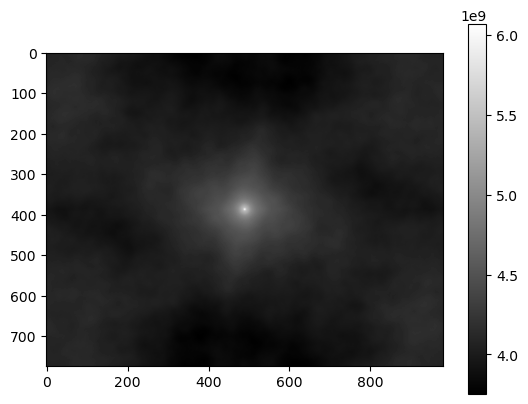

c:\ProgramData\anaconda3\Lib\site-packages\scipy\optimize\_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


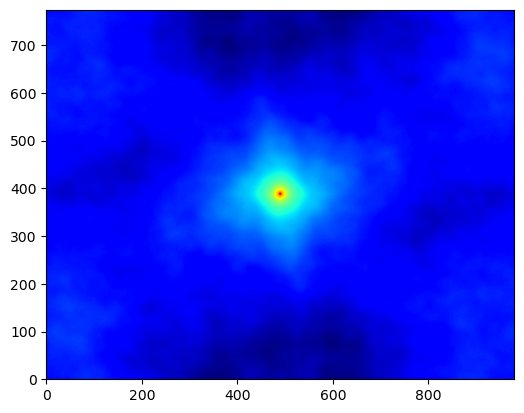

In [8]:
import scipy.optimize as opt
import numpy as np
import pylab as plt
from PIL import Image

def auto_correlation(frame):
    """
    Returns the computed auto_correlation for a given frame.

    Parameter frame: an SEM image
    """

    ft = np.fft.fft2(frame)
    autocorr = np.fft.ifft2(ft * np.conjugate(ft))
    return np.fft.fftshift(autocorr).real

#define model function and pass independant variables x and y as a list
def twoD_Gaussian(xy, amplitude, xo, yo, sigma_x, sigma_y, theta, offset):
    x, y = xy
    xo = float(xo)
    yo = float(yo)    
    a = (np.cos(theta)**2)/(2*sigma_x**2) + (np.sin(theta)**2)/(2*sigma_y**2)
    b = -(np.sin(2*theta))/(4*sigma_x**2) + (np.sin(2*theta))/(4*sigma_y**2)
    c = (np.sin(theta)**2)/(2*sigma_x**2) + (np.cos(theta)**2)/(2*sigma_y**2)
    g = offset + amplitude*np.exp( - (a*((x-xo)**2) + 2*b*(x-xo)*(y-yo) + c*((y-yo)**2)))
    return g.ravel()

def gaussian2d_with_offset(xy, amplitude, centerx, centery, sigmax, sigmay, correlation, offset):
    """
    Returns a bivariate normal distribution equation for a given set of parameters.

    Parameter x: a numpy meshgrid representing the x-axis
    Parameter y: a numpy meshgrid representing the y-axis
    Parameter amplitude: a number representing the amplitude of the distribution
    Parameter centerx: a number representing the mean value of the x-values
    Parameter centery: a number representing the mean value of the y-values
    Parameter sigmax: a number representing the standard deviation in the x-direction
    Parameter sigmay: a number representing the standard deviation in the y-direction
    Parameter correlation: a number representing the correlation between the two indepedent variables x and y
    Parameter offset: a number representing the offset between the distribution and the x = y = 0 plane
    """
    x, y = xy
    xterm = (x - centerx) / sigmax 
    yterm = (y - centery) / sigmay
    exponent = (-1 / (2 * (1 - correlation**2))) * (xterm**2 + yterm**2 - 2 * correlation * xterm * yterm)
    constant = amplitude / (2 * np.pi * sigmax * sigmay * np.sqrt(1 - correlation**2))
    return (constant * np.exp(exponent) + offset).ravel()

image_path = "semtest.jpg"
img = Image.open(image_path).convert('L')
img_array = np.array(img)
acdata = auto_correlation(img_array)
plt.imshow(acdata, cmap = 'gray')
plt.colorbar()
plt.show()

# Create x and y indices
#x = np.linspace(0, 200, 201)
#y = np.linspace(0, 200, 201)
#x,y = np.meshgrid(x, y)

nrows = len(acdata)
ncols = len(acdata[0])
x, y = np.meshgrid(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows)) # creates the x and y array values

#create data
#data = twoD_Gaussian((x, y), 3, 100, 100, 20, 40, 0, 10)

# plot twoD_Gaussian data generated above
#plt.figure()
#plt.imshow(data.reshape(201, 201))
#plt.colorbar()

# add some noise to the data and try to fit the data generated beforehand
initial_guess = (100,100,100,20,40,0,100)

#data_noisy = data + 0.2*np.random.normal(size=len(x))

popt, pcov = opt.curve_fit(gaussian2d_with_offset, (x,y), acdata.ravel(), p0 = initial_guess)

data_fitted = gaussian2d_with_offset((x, y), *popt)

fig, ax = plt.subplots(1, 1)
#ax.hold(True) For older versions. This has now been deprecated and later removed
ax.imshow(acdata.reshape(nrows, ncols), cmap=plt.cm.jet, origin='lower',
    extent=(x.min(), x.max(), y.min(), y.max()))
ax.contour(x, y, data_fitted.reshape(nrows, ncols), 8, colors='w')
plt.show()

In [7]:
import numpy as np
import warnings

#print(minimize(np.poly1d([1, -3, 2, -9]), 1))

x = [-0.5, 0, 0.61, 1.64, 2.18]
y = [-8, -9, -8.8, -9.62, -8]

def minimum(x, y, degree):
    """
    Calculates the minimum value and the position of its occurence given a data set x and y 
    and the degree of the polynomial to be fitted.

    Parameter x: a 1D list of x-coordinates
    Parameter y: a 1D list of corresponding y-coordinates
    Parameter degree: an int representing the maximum degree of the polynomial to be fitted
    """

    warnings.filterwarnings("error", category=np.RankWarning)

    eqn = None

    while eqn is None:
        try:
            coeff = np.polyfit(x, y, degree) # fits the data to a polynomial equation that is a good fit (doesn't give a RankWarning)
            eqn = np.poly1d(coeff)  

        except:                                                 
            degree = degree - 1

    derivative = eqn.deriv()
    local_mins = np.roots(derivative.c)
    min_vals = []

    for val in local_mins:
        min_vals.append(eqn(val))

    small_val = min(min_vals)
    small_pos = local_mins[min_vals.index(small_val)]

    return {"min_val": small_val, "min_x": small_pos, "fitted_eqn": eqn}

minimum(x, y, 4)

{'min_val': -9.620044380447489,
 'min_x': 1.6436166992706087,
 'fitted_eqn': poly1d([ 1.01633089, -3.07882957,  2.11357187, -0.04646531, -9.        ])}